In [1]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import RandomForestRegressor

DATA_PATH = Path("..") / "opsd-time_series-2020-10-06"

In [2]:
df = pd.read_csv(DATA_PATH / "load_with_weather.csv", index_col = 0)

In [3]:
df.index = pd.to_datetime(df.index, utc = True).tz_convert("Europe/Prague")

In [4]:
df[df['CZ_temperature'].isna()]

,CZ_load_actual_entsoe_transparency,CZ_solar_generation_actual,CZ_wind_onshore_generation_actual,CZ_temperature,CZ_radiation_direct_horizontal,CZ_radiation_diffuse_horizontal
cet_cest_timestamp,,,,,,
2020-01-01 01:00:00+01:00,5549.62,0.0,99.92,NaN,NaN,NaN
2020-01-01 02:00:00+01:00,5559.53,0.0,90.62,NaN,NaN,NaN
2020-01-01 03:00:00+01:00,5496.27,0.0,104.40,NaN,NaN,NaN
2020-01-01 04:00:00+01:00,5499.57,0.0,103.54,NaN,NaN,NaN
2020-01-01 05:00:00+01:00,5505.09,0.0,62.98,NaN,NaN,NaN
...,...,...,...,...,...,...
2020-09-30 21:00:00+02:00,7605.02,NaN,58.73,NaN,NaN,NaN
2020-09-30 22:00:00+02:00,7173.36,NaN,60.90,NaN,NaN,NaN
2020-09-30 23:00:00+02:00,6763.14,NaN,57.06,NaN,NaN,NaN


Since the weather data are missing for 2020 I'll use 2015, 2016, 2017 as a training sets, 2018 as a validation and 2019 as the test set

In [5]:
df = df[df.index.year != 2020]
df.shape

(43824, 6)

In [6]:
df.isna().sum()

CZ_load_actual_entsoe_transparency    109
CZ_solar_generation_actual             29
CZ_wind_onshore_generation_actual      15
CZ_temperature                          0
CZ_radiation_direct_horizontal          0
CZ_radiation_diffuse_horizontal         0
dtype: int64

In [7]:
# now I'll do some basic imputation
# for the missing solar generation numbers I'll fill in zeros for all the observations where both direct and diffuse radiation was zero
no_sun = (df['CZ_radiation_direct_horizontal'] == 0) & (df['CZ_radiation_diffuse_horizontal'] == 0)
df.loc[no_sun, 'CZ_solar_generation_actual'] = df.loc[no_sun, 'CZ_solar_generation_actual'].fillna(0)

df.isna().sum()

CZ_load_actual_entsoe_transparency    109
CZ_solar_generation_actual              8
CZ_wind_onshore_generation_actual      15
CZ_temperature                          0
CZ_radiation_direct_horizontal          0
CZ_radiation_diffuse_horizontal         0
dtype: int64

There are still some missing values but the numbers are very low now so I'll just drop them after the feature engineering

In [8]:
# creating the function that will implement the features
# I'm creating features that will work for a one day ahead prediction (at midnight it will be possible to predict the whole upcomming day)
def create_features(df):
    df['is_weekend'] = ((df.index.day_of_week == 5) | (df.index.day_of_week == 6)).astype(int)
    df['hour'] = df.index.hour
    df['day_of_week'] = df.index.day_of_week
    df['month'] = df.index.month
    
    df['dir_lag_24'] = df['CZ_radiation_direct_horizontal'].shift(24)
    df['dir_lag_48'] = df['CZ_radiation_direct_horizontal'].shift(48)
    df['dir_lag_168'] = df['CZ_radiation_direct_horizontal'].shift(168)
    
    df['diff_lag_24'] = df['CZ_radiation_diffuse_horizontal'].shift(24)
    df['diff_lag_48'] = df['CZ_radiation_diffuse_horizontal'].shift(48)
    df['diff_lag_168'] = df['CZ_radiation_diffuse_horizontal'].shift(168)
    
    df['temp_lag_24'] = df['CZ_temperature'].shift(24)
    df['temp_lag_48'] = df['CZ_temperature'].shift(48)
    df['temp_lag_168'] = df['CZ_temperature'].shift(168)
    
    df['gen_lag_24'] = df['CZ_solar_generation_actual'].shift(24)
    df['gen_lag_48'] = df['CZ_solar_generation_actual'].shift(48)
    df['gen_lag_168'] = df['CZ_solar_generation_actual'].shift(168)
    
    # here every hour in a day will have a daily average of the previous day
    daily_prev_mean = df['CZ_radiation_diffuse_horizontal'].resample('D').mean().shift(1)
    df['prev_day_mean_diff'] = df.index.normalize().map(daily_prev_mean)
    
    daily_prev_mean = df['CZ_radiation_direct_horizontal'].resample('D').mean().shift(1)
    df['prev_day_mean_dirr'] = df.index.normalize().map(daily_prev_mean)
        
    daily_prev_mean = df['CZ_temperature'].resample('D').mean().shift(1)
    df['prev_day_mean_temp'] = df.index.normalize().map(daily_prev_mean)
    
    daily_prev_mean = df['CZ_solar_generation_actual'].resample('D').mean().shift(1)
    df['prev_day_mean_gen'] = df.index.normalize().map(daily_prev_mean)
    
    # encoding hour, day of week and day of year using cos sin encoding so the model knows that it's cycle
    df['hour_sin'] = np.sin(2 * np.pi * df.index.hour / 24.0)
    df['hour_cos'] = np.cos(2 * np.pi * df.index.hour / 24.0)
    
    df['dow_sin'] = np.sin(2 * np.pi * df.index.day_of_week / 7.0)
    df['dow_cos'] = np.cos(2 * np.pi * df.index.day_of_week / 7.0)
    
    df['doy_sin'] = np.sin(2 * np.pi * df.index.day_of_year / 365)
    df['doy_cos'] = np.cos(2 * np.pi * df.index.day_of_year / 365)
    
    
    
    return df

Here I'm gonna create the features and drop the missing values and split the data into train, val and test sets.

In [9]:
df = create_features(df)

target = 'CZ_solar_generation_actual'
features = ['is_weekend', 'hour', 'day_of_week', 'month',
            'dir_lag_24', 'dir_lag_48', 'dir_lag_168',
            'diff_lag_24', 'diff_lag_48', 'diff_lag_168',
            'temp_lag_24', 'temp_lag_48', 'temp_lag_168',
            'gen_lag_24', 'gen_lag_48', 'gen_lag_168',
            'prev_day_mean_diff', 'prev_day_mean_dirr', 'prev_day_mean_temp', 'prev_day_mean_gen',
            'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'doy_sin', 'doy_cos']

df_model = df.dropna(subset=features + [target])

train = df_model[df_model.index.year <= 2017].copy()
val = df_model[df_model.index.year == 2018].copy()
test = df_model[df_model.index.year == 2019].copy()

print(f"Length of train: {len(train)}, val: {len(val)}, test: {len(test)}.")

Length of train: 26107, val: 8760, test: 8760.


Here I create two baselines, one, that just takes the seasonal average for the same month and hour. And the second one just predicts the same values as yesterday.

In [10]:
# seasonal average baseline computed only from the train set
seasonal_avg = train.groupby(['month', 'hour'])[target].mean().rename('seasonal_avg')

for d in (train, val, test):
    d['seasonal_avg'] = seasonal_avg.reindex(pd.MultiIndex.from_arrays([d['month'], d['hour']])).values
    d['persistence'] = d['gen_lag_24']

### model fitting
Here I will fit 9 random forests with different hyperparameters to see which one performs the best.

In [11]:
rf_params = {
    'RF 1': dict(max_features=1.0, min_samples_leaf=1),
    'RF 2': dict(max_features=0.5, min_samples_leaf=1),
    'RF 3': dict(max_features='sqrt', min_samples_leaf=1),
    'RF 4': dict(max_features=1.0, min_samples_leaf=5),
    'RF 5': dict(max_features=0.5, min_samples_leaf=5),
    'RF 6': dict(max_features='sqrt', min_samples_leaf=5),
    'RF 7': dict(max_features=1.0, min_samples_leaf=20),
    'RF 8': dict(max_features=0.5, min_samples_leaf=20),
    'RF 9': dict(max_features='sqrt', min_samples_leaf=20)
}

rf_models = {}
for name, params in rf_params.items():
    model = RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42, **params)
    model.fit(train[features], train[target])
    rf_models[name] = model
    val[name] = model.predict(val[features])
    print(f"{name} fitted")

RF 1 fitted
RF 2 fitted
RF 3 fitted
RF 4 fitted
RF 5 fitted
RF 6 fitted
RF 7 fitted
RF 8 fitted
RF 9 fitted


### Evaluation
I use MAE and RMSE in MW, plus normalised MAE (MAE divided by the average generation)

In [12]:
def evaluate(df, pred_col):
    err = df[target] - df[pred_col]
    return {'MAE': err.abs().mean(),
            'RMSE': np.sqrt((err ** 2).mean()),
            'nMAE (%)': err.abs().mean() / df[target].mean() * 100}

# comparing all models on the validation set
val_results = pd.DataFrame({name: evaluate(val, name)
                            for name in ['seasonal_avg', 'persistence', *rf_models]}).T.round(2)
val_results

,MAE,RMSE,nMAE (%)
seasonal_avg,84.80,169.49,31.85
persistence,78.31,171.73,29.42
RF 1,75.92,154.42,28.52
RF 2,75.88,153.77,28.50
RF 3,75.13,152.08,28.22
RF 4,75.42,153.63,28.33
RF 5,75.11,152.13,28.21
RF 6,74.41,150.80,27.95
RF 7,74.45,151.16,27.97
RF 8,73.78,149.67,27.71


In [13]:
# choosing the random forest with the lowest validation MAE
best_name = val_results.loc[list(rf_models), 'MAE'].idxmin()
best_rf = rf_models[best_name]
print(f"Best model on validation: {best_name} {rf_params[best_name]}")

# refitting the chosen model on train + validation before testing
train_val = pd.concat([train, val])

final_rf = RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42, **rf_params[best_name])
final_rf.fit(train_val[features], train_val[target])
test['rf_pred'] = final_rf.predict(test[features])

# the seasonal baseline also gets train + validation data, so the comparison is fair
seasonal_avg_tv = train_val.groupby(['month', 'hour'])[target].mean()
test['seasonal_avg'] = seasonal_avg_tv.reindex(pd.MultiIndex.from_arrays([test['month'], test['hour']])).values

test_results = pd.DataFrame({
    'Seasonal average': evaluate(test, 'seasonal_avg'),
    'Persistence': evaluate(test, 'persistence'),
    f'Random forest ({best_name})': evaluate(test, 'rf_pred'),
}).T.round(2)
test_results

Best model on validation: RF 8 {'max_features': 0.5, 'min_samples_leaf': 20}


,MAE,RMSE,nMAE (%)
Seasonal average,85.13,168.91,33.16
Persistence,84.20,182.10,32.79
Random forest (RF 8),74.89,153.56,29.17


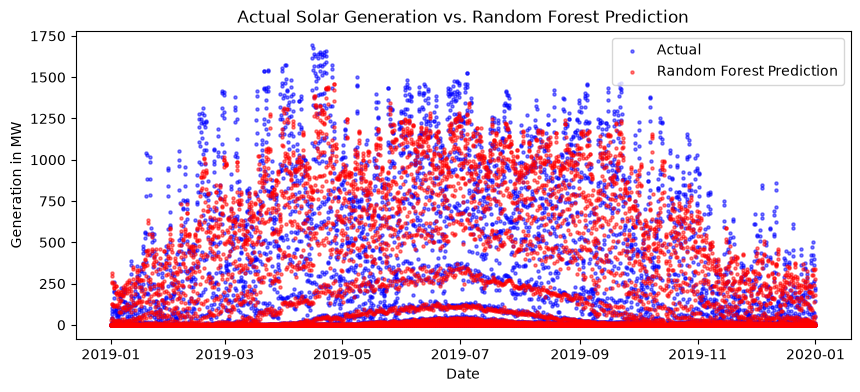

In [14]:
# plotting the best random forest on the test set
fig, ax = plt.subplots(figsize = (10, 4))

ax.scatter(test.index, test[target], label = 'Actual', color = 'blue', alpha = 0.5, s = 5)
ax.scatter(test.index, test['rf_pred'], label = 'Random Forest Prediction', color = 'red', alpha = 0.5, s = 5)
ax.set_title('Actual Solar Generation vs. Random Forest Prediction')
ax.set_ylabel('Generation in MW')
ax.set_xlabel('Date')
ax.legend()
plt.show()

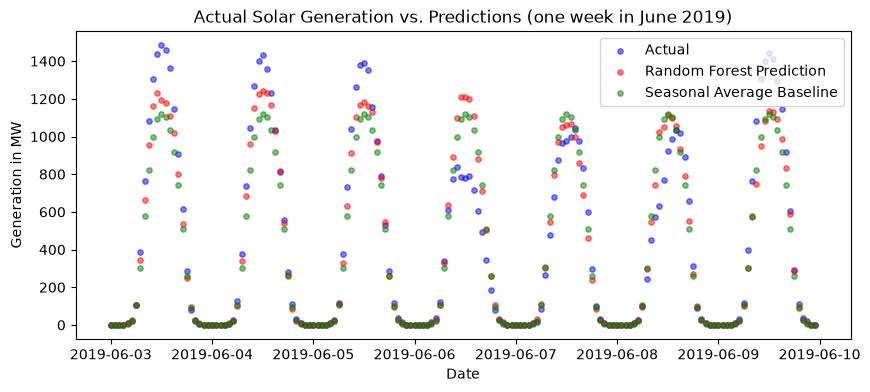

In [15]:
# same plot for one week in summer, because a week in January has almost no sun to show
week = test.loc['2019-06-03':'2019-06-09']

fig, ax = plt.subplots(figsize = (10, 4))

ax.scatter(week.index, week[target], label = 'Actual', color = 'blue', alpha = 0.5, s = 15)
ax.scatter(week.index, week['rf_pred'], label = 'Random Forest Prediction', color = 'red', alpha = 0.5, s = 15)
ax.scatter(week.index, week['seasonal_avg'], label = 'Seasonal Average Baseline', color = 'green', alpha = 0.5, s = 15)
ax.set_title('Actual Solar Generation vs. Predictions (one week in June 2019)')
ax.set_ylabel('Generation in MW')
ax.set_xlabel('Date')
ax.legend()
plt.show()

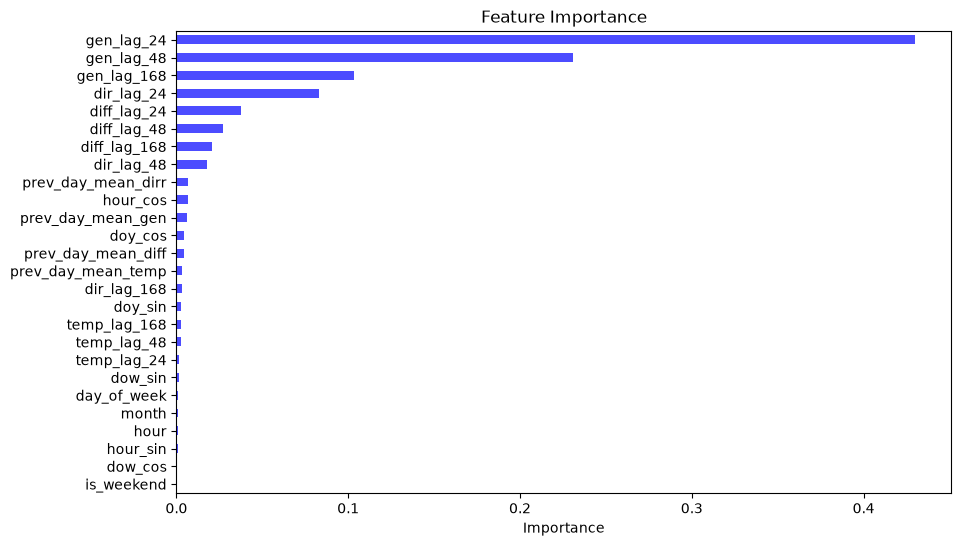

In [18]:
# most important predictors of the best random forest
importances = pd.Series(final_rf.feature_importances_, index=features).sort_values(ascending=False)

fig, ax = plt.subplots(figsize = (10, 6))
importances.sort_values().plot.barh(ax = ax, color = 'blue', alpha = 0.7)
ax.set_title(f'Feature Importance')
ax.set_xlabel('Importance')
plt.show()

In [17]:
# average error by how much the sun actually produced
test['error'] = test['rf_pred'] - test[target]

levels = pd.cut(test[target], bins = [-1, 0, 200, 600, 1000, 2000],
                labels = ['0', '0-200', '200-600', '600-1000', 'above 1000'])

error_table = test.groupby(levels, observed = True)['error'].agg(['mean', 'count']).round(1)
error_table.columns = ['Average error in MWh', 'Number of hours']
error_table.index.name = 'Actual generation in MWh'
error_table

,Average error in MWh,Number of hours
Actual generation in MWh,,
0,3.0,3358
0-200,29.1,2484
200-600,75.1,1238
600-1000,-26.6,969
above 1000,-238.6,711
